<a href="https://colab.research.google.com/github/Kavishka2401/GPTea/blob/C_1_Yield_Prediction/Machine_Learning_Pipeline/Preprocessing_and_ModelTraining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import Google Drive to get the final dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np

final_data_path = '/content/drive/MyDrive/DSGP_DOCS/Datasets/Final_Data_Merged.csv'

# Load final data
final_data = pd.read_csv(final_data_path)
df = final_data.copy()

In [3]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.0 MB/s eta 0:00:00


In [40]:
# GENERAL PURPOSE LIBRARIES
import matplotlib.pyplot as plt
import seaborn as sns

# SKLEARN TOOLS
from sklearn.linear_model import Lasso, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# XGBOOST
from xgboost import XGBRegressor

# CATBOOST
from catboost import CatBoostRegressor

# Neural Networks
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

In [5]:
import joblib
import os

## **Data Preprocessing**

### Remove Missing Rows

In [6]:
# Keep rows where YPH is not missing
df = df[df['YPH'].notna()]

### Data Type Conversion

In [7]:
month_map = {
    'January':1,'February':2,'March':3,'April':4,'May':5,'June':6,
    'July':7,'August':8,'September':9,'October':10,'November':11,'December':12
}
df['Month'] = df['Month'].map(month_map)

### Remove irrelevant columns

In [8]:
df = df.drop(columns=['Month'])

In [9]:
# Remove highly correlated features
df = df.drop(columns=['temperature_2m_min',
                      'temperature_2m_max',
                      'relative_humidity_2m_min',
                      'relative_humidity_2m_max',
                      'wind_speed_10m_max',
                      'precipitation_sum',
                      'UT925',
                      'BioShakthi',
                      'Zinc',
                      'sunshine_duration',
                      'relative_humidity_2m_mean'])

# Display remaining columns to verify
print("Remaining columns after dropping redundant weather features:")
print(df.columns)

Remaining columns after dropping redundant weather features:
Index(['Year', 'YPH', 'T200', 'U709', 'Epson Salt', 'Dolomite', 'Urea',
       'Compost', 'BioShield', 'temperature_2m_mean', 'rain_sum',
       'wind_speed_10m_mean', 'et0_fao_evapotranspiration'],
      dtype='object')


In [ ]:
# Define final file path
final_data_path = "/content/drive/MyDrive/DSGP_DOCS/Datasets/Final_Data_Preprocessed.csv"

# Save the preprocessed DataFrame
df.to_csv(final_data_path, index=False)

print(f"Preprocessed dataset saved successfully at:\n{final_data_path}")

Preprocessed dataset saved successfully at:
/content/drive/MyDrive/DSGP_DOCS/Datasets/Final_Data_Preprocessed.csv


# **CatBoost**

### Model Based Preprocessing

In [17]:
# Create copy
df_catboost = df.copy()

# Feature Engineering
df_catboost['Year_trend'] = df_catboost['Year'] - df_catboost['Year'].min()

# YPH lags
for lag in [1, 12]:
    df_catboost[f'YPH_lag{lag}'] = df_catboost['YPH'].shift(lag).bfill()

# Fertilizer lags
for fert in ['Compost']:
    df_catboost[f'{fert}_lag1'] = df_catboost[fert].shift(1).fillna(0)

# Target & Features
target = 'YPH'
features = [col for col in df_catboost.columns if col not in ['YPH', 'Year']]

# Walk Forward Validation test years
all_years = sorted(df_catboost['Year'].unique())
test_years = [y for y in all_years if all(ty in all_years for ty in [y-3, y-2, y-1])]

# Data Augmentation
def add_gaussian_noise(X, y, noise_std=0.03, n_augmentations=2):
    X_aug = [X.values.copy()]
    y_aug = [y.values.copy()]

    for _ in range(n_augmentations):
        noise = np.random.normal(0, noise_std * X.std(), X.shape)

        # Reduce noise for lag features
        lag_cols = [col for col in X.columns if 'YPH_lag' in col]
        for col in lag_cols:
            noise[:, X.columns.get_loc(col)] *= 0.7

        X_aug.append(X.values + noise)
        y_noise = np.random.normal(0, noise_std * 0.5 * y.std(), y.shape)
        y_aug.append(y.values + y_noise)

    return np.vstack(X_aug), np.hstack(y_aug)

### Model Training

In [18]:
train_results = []
test_results = []

for test_year in test_years:

    train_years = [test_year - 3, test_year - 2, test_year - 1]

    train_df = df_catboost[df_catboost['Year'].isin(train_years)]
    test_df  = df_catboost[df_catboost['Year'] == test_year]

    X_train = train_df[features]
    y_train = train_df[target]

    X_test = test_df[features]
    y_test = test_df[target]

    # Augment training data
    X_train_aug, y_train_aug = add_gaussian_noise(X_train, y_train)

    # Model
    model = CatBoostRegressor(
        iterations=300,
        depth=3,
        learning_rate=0.025,
        l2_leaf_reg=15,
        min_data_in_leaf=25,
        subsample=0.7,
        random_strength=1.0,
        loss_function='RMSE',
        random_seed=42,
        verbose=False
    )

    # Training
    model.fit(
        X_train_aug, y_train_aug,
        eval_set=(X_test, y_test),
        early_stopping_rounds=50
    )

    # Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)

    # Store metrics for evaluation
    train_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'mae': mean_absolute_error(y_train, y_train_pred),
        'mse': mean_squared_error(y_train, y_train_pred),
        'r2': r2_score(y_train, y_train_pred)
    })

    test_results.append({
        'year': test_year,
        'train_years': train_years,
        'rmse': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'mae': mean_absolute_error(y_test, y_test_pred),
        'mse': mean_squared_error(y_test, y_test_pred),
        'r2': r2_score(y_test, y_test_pred)
    })

### Model Evaluation and Visualization


TRAIN METRICS PER YEAR
   year      rmse       mae        mse        r2
0  2020  3.802707  2.990933  14.460584  0.974983
1  2021  2.942114  2.160048   8.656036  0.985391
2  2022  2.533189  1.816377   6.417045  0.990015
3  2023  2.592677  1.944636   6.721974  0.990118
4  2024  2.639055  1.944734   6.964611  0.989800
5  2025  2.511837  1.722636   6.309326  0.990794

TEST METRICS PER YEAR
   year         train_years       rmse        mae         mse        r2
0  2020  [2017, 2018, 2019]  10.709513   8.608913  114.693670  0.809924
1  2021  [2018, 2019, 2020]  13.620841  10.033048  185.527299  0.698887
2  2022  [2019, 2020, 2021]   9.093681   5.877774   82.695030  0.865785
3  2023  [2020, 2021, 2022]   8.060652   5.162657   64.974117  0.894546
4  2024  [2021, 2022, 2023]   8.948448   5.820380   80.074714  0.870585
5  2025  [2022, 2023, 2024]  10.179373   6.804860  103.619640  0.832532

Average Train Metrics
rmse    2.836930
mae     2.096561
mse     8.254929
r2      0.986850
dtype: float64


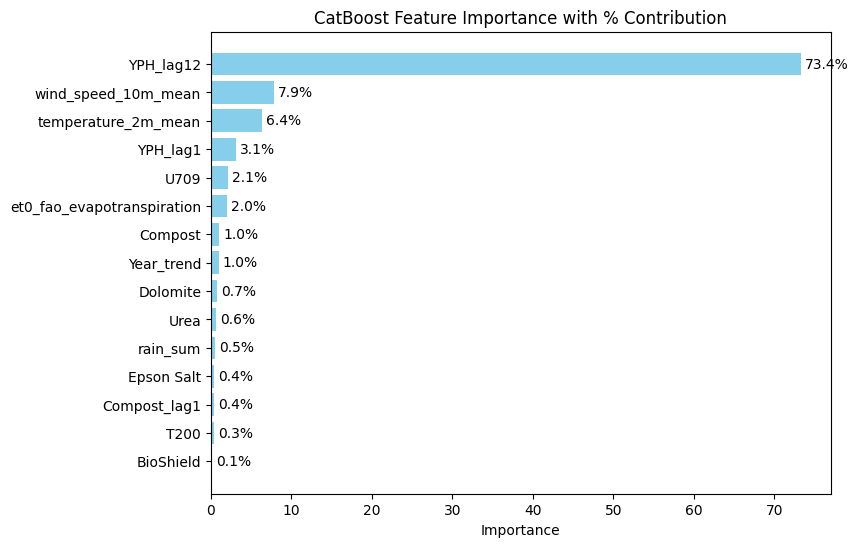

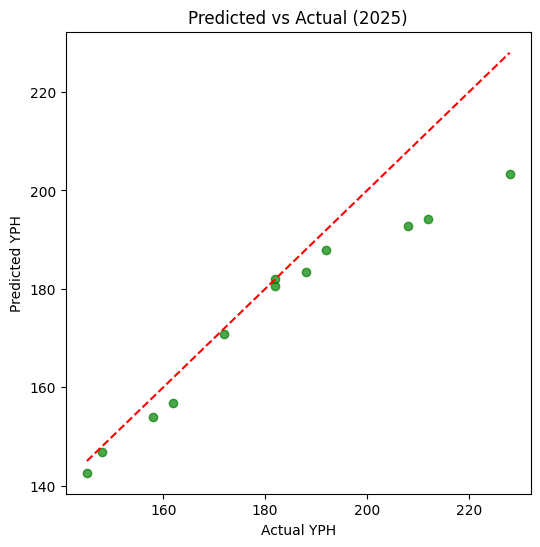

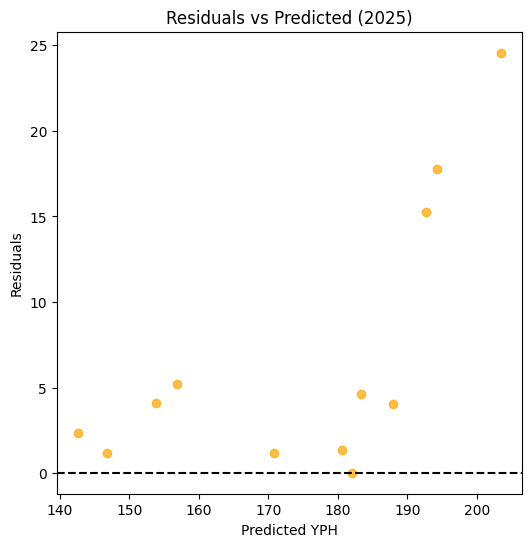

In [19]:
# Results DataFrames
train_metrics_df = pd.DataFrame(train_results)
test_metrics_df  = pd.DataFrame(test_results)

# Print Metrics
print("\nTRAIN METRICS PER YEAR")
print(train_metrics_df)

print("\nTEST METRICS PER YEAR")
print(test_metrics_df)

print("\nAverage Train Metrics")
print(train_metrics_df[['rmse','mae','mse','r2']].mean())

print("\nAverage Test Metrics")
print(test_metrics_df[['rmse','mae','mse','r2']].mean())

# Feature Importance
feature_importance = pd.DataFrame({
    'feature': features,
    'importance': model.get_feature_importance()
})

# Calculate percentage contribution
feature_importance['percentage'] = (feature_importance['importance'] / feature_importance['importance'].sum()) * 100
feature_importance = feature_importance.sort_values(by='importance', ascending=False)

# Plot feature importance
plt.figure(figsize=(8,6))
bars = plt.barh(feature_importance['feature'], feature_importance['importance'], color='skyblue')
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("CatBoost Feature Importance with % Contribution")

# Percentage labels to bars
for bar, pct in zip(bars, feature_importance['percentage']):
    plt.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
             f"{pct:.1f}%", va='center')

plt.show()

# Predicted vs Actual Plot
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_test_pred, color='green', alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
plt.xlabel("Actual YPH")
plt.ylabel("Predicted YPH")
plt.title(f"Predicted vs Actual ({test_year})")
plt.show()

# Residuals vs Predicted Plot
residuals = y_test - y_test_pred
plt.figure(figsize=(6,6))
plt.scatter(y_test_pred, residuals, color='orange', alpha=0.7)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel("Predicted YPH")
plt.ylabel("Residuals")
plt.title(f"Residuals vs Predicted ({test_year})")
plt.show()

### Save Model

In [ ]:
# Path to save
save_path = '/content/drive/MyDrive/DSGP_DOCS/Final_Models/catboost_model.cbm'
os.makedirs(os.path.dirname(save_path), exist_ok=True)

# Save CatBoost model
model.save_model(save_path)
print(f"CatBoost model saved at: {save_path}")

CatBoost model saved at: /content/drive/MyDrive/DSGP_DOCS/Final_Models/catboost_model.cbm


# **XGBoost**

### Model Based Preprocessing

In [20]:
# Create copy
df_xgb = df.copy()

# YPH lags (1, 6, 12 months)
for lag in [1, 12]:
    df_xgb[f'YPH_lag{lag}'] = df_xgb['YPH'].shift(lag).bfill()

# Fertilizer lags (1 month)
for fert in ['Compost']:
    df_xgb[f'{fert}_lag1'] = df_xgb[fert].shift(1).fillna(0)

# Target and features
target = 'YPH'
features = [col for col in df_xgb.columns if col not in ['YPH', 'Year']]

# Settings
TEST_YEARS = sorted(df_xgb[df_xgb['Year'] >= 2020]['Year'].unique())
WINDOW_SIZE = 3

### Model Training

In [21]:
# Clear previous results
train_results = []
test_results  = []

# Store last pipeline for plotting
last_pipeline = None

for test_year in TEST_YEARS:
    # Define train years
    train_years = [test_year - i for i in range(WINDOW_SIZE, 0, -1)]
    train_df = df_xgb[df_xgb['Year'].isin(train_years)].copy()
    test_df  = df_xgb[df_xgb['Year'] == test_year].copy()

    X_train = train_df[features]
    y_train = train_df[target]
    X_test = test_df[features]
    y_test = test_df[target]

    print(f"Test Year {test_year} | Train Years {train_years}")

    # XGBoost pipeline
    pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('xgb', XGBRegressor(
            n_estimators=200,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.7,
            colsample_bytree=0.7,
            reg_alpha=1.0,
            reg_lambda=10.0,
            objective='reg:squarederror',
            random_state=42
        ))
    ])

    # Train
    pipeline.fit(X_train, y_train)

    # Predictions
    y_train_pred = pipeline.predict(X_train)
    y_test_pred  = pipeline.predict(X_test)

    # Save metrics
    train_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'mae': mean_absolute_error(y_train, y_train_pred),
        'mse': mean_squared_error(y_train, y_train_pred),
        'r2': r2_score(y_train, y_train_pred)
    })

    test_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'mae': mean_absolute_error(y_test, y_test_pred),
        'mse': mean_squared_error(y_test, y_test_pred),
        'r2': r2_score(y_test, y_test_pred)
    })

    # Last pipeline for plots
    last_pipeline = pipeline
    last_y_test = y_test
    last_y_test_pred = y_test_pred

Test Year 2020 | Train Years [np.int64(2017), np.int64(2018), np.int64(2019)]
Test Year 2021 | Train Years [np.int64(2018), np.int64(2019), np.int64(2020)]
Test Year 2022 | Train Years [np.int64(2019), np.int64(2020), np.int64(2021)]
Test Year 2023 | Train Years [np.int64(2020), np.int64(2021), np.int64(2022)]
Test Year 2024 | Train Years [np.int64(2021), np.int64(2022), np.int64(2023)]
Test Year 2025 | Train Years [np.int64(2022), np.int64(2023), np.int64(2024)]


### Model Evaluation and Visualization


TRAIN METRICS PER YEAR
   year      rmse       mae        mse        r2
0  2020  3.957700  2.265965  15.663389  0.972902
1  2021  3.552526  1.552286  12.620441  0.978700
2  2022  3.687050  2.000908  13.594340  0.978847
3  2023  3.879993  1.780688  15.054345  0.977869
4  2024  3.796249  1.666957  14.411503  0.978894
5  2025  3.643025  1.685076  13.271632  0.980635

TEST METRICS PER YEAR
   year       rmse       mae         mse        r2
0  2020  11.581827  8.993788  134.138718  0.777699
1  2021  13.167454  9.650757  173.381851  0.718599
2  2022  11.548328  7.328802  133.363876  0.783549
3  2023   9.543261  6.234373   91.073830  0.852186
4  2024  10.368301  6.973051  107.501656  0.826258
5  2025  11.992846  8.997711  143.828354  0.767548

AVERAGE TRAIN METRICS
rmse     3.752757
mae      1.825313
mse     14.102609
r2       0.977975
dtype: float64

AVERAGE TEST METRICS
rmse     11.367003
mae       8.029747
mse     130.548047
r2        0.787640
dtype: float64


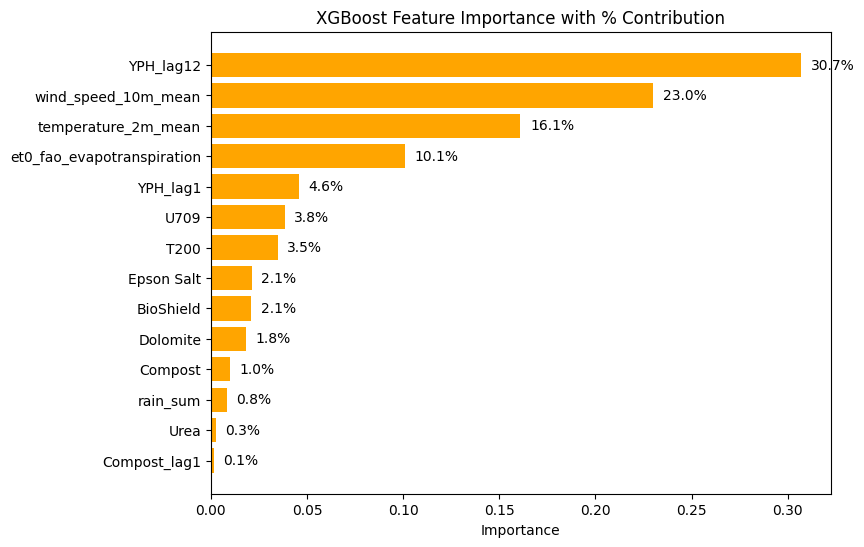

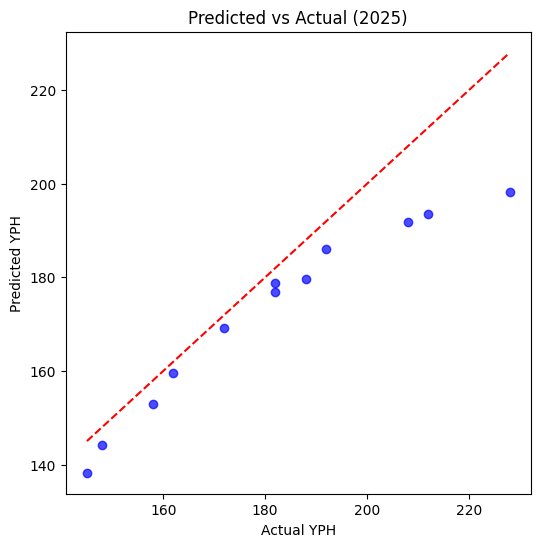

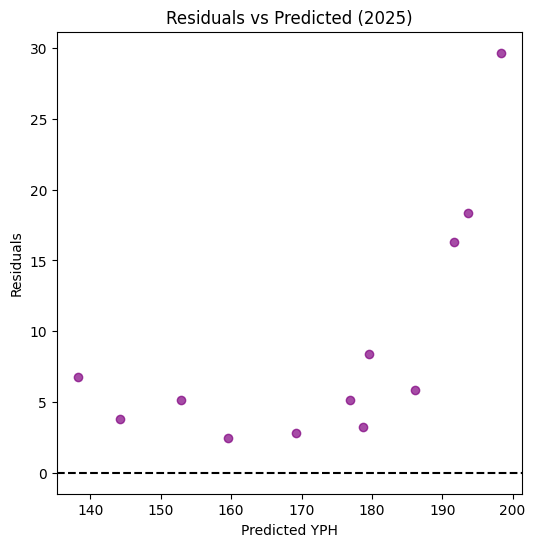

In [22]:
# Convert metrics to DataFrame
train_metrics_df = pd.DataFrame(train_results)
test_metrics_df  = pd.DataFrame(test_results)

print("\nTRAIN METRICS PER YEAR")
print(train_metrics_df)

print("\nTEST METRICS PER YEAR")
print(test_metrics_df)

print("\nAVERAGE TRAIN METRICS")
print(train_metrics_df[['rmse','mae','mse','r2']].mean())

print("\nAVERAGE TEST METRICS")
print(test_metrics_df[['rmse','mae','mse','r2']].mean())

# Feature importance with percentages
xgb_model = last_pipeline.named_steps['xgb']
feat_imp = pd.DataFrame({
    'feature': features,
    'importance': xgb_model.feature_importances_
})
feat_imp['percentage'] = (feat_imp['importance'] / feat_imp['importance'].sum()) * 100
feat_imp = feat_imp.sort_values(by='importance', ascending=False)

# Plot feature importance
plt.figure(figsize=(8,6))
bars = plt.barh(feat_imp['feature'], feat_imp['importance'], color='orange')
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("XGBoost Feature Importance with % Contribution")
# Add percentage labels
for bar, pct in zip(bars, feat_imp['percentage']):
    plt.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
             f"{pct:.1f}%", va='center')
plt.show()

# Predicted vs Actual
plt.figure(figsize=(6,6))
plt.scatter(last_y_test, last_y_test_pred, alpha=0.7, color='blue')
plt.plot([last_y_test.min(), last_y_test.max()],
         [last_y_test.min(), last_y_test.max()],
         'r--')
plt.xlabel("Actual YPH")
plt.ylabel("Predicted YPH")
plt.title(f"Predicted vs Actual ({TEST_YEARS[-1]})")
plt.show()

# Residuals vs Predicted
residuals = last_y_test - last_y_test_pred
plt.figure(figsize=(6,6))
plt.scatter(last_y_test_pred, residuals, alpha=0.7, color='purple')
plt.axhline(0, linestyle='--', color='black')
plt.xlabel("Predicted YPH")
plt.ylabel("Residuals")
plt.title(f"Residuals vs Predicted ({TEST_YEARS[-1]})")
plt.show()

### Save Model

In [ ]:
# Save path
save_path = '/content/drive/MyDrive/DSGP_DOCS/Final_Models/xgb_model.pkl'
os.makedirs(os.path.dirname(save_path), exist_ok=True)

# Save the XGBoost model (from pipeline)
joblib.dump(last_pipeline, save_path)
print(f"XGBoost pipeline saved at: {save_path}")

XGBoost pipeline saved at: /content/drive/MyDrive/DSGP_DOCS/Final_Models/xgb_model.pkl


# **Random Forest**

### Model Based Preprocessing

In [23]:
# Create a copy of the dataframe
df_rf = df.copy()

# Create lag features for YPH (1, 6, 12 months)
for lag in [1, 12]:
    df_rf[f'YPH_lag{lag}'] = df_rf['YPH'].shift(lag).bfill()

# Create lag features for fertilizers (1-month lag)
for fert in ['Compost']:
    df_rf[f'{fert}_lag1'] = df_rf[fert].shift(1).fillna(0)

# Define target and features
target = 'YPH'
features = [col for col in df_rf.columns if col not in ['YPH', 'Year']]

# Walk-forward validation setup
TEST_YEARS = sorted(df_rf[df_rf['Year'] >= 2020]['Year'].unique())
WINDOW_SIZE = 3

# Clear previous results
train_results = []
test_results  = []

### Model Training

In [24]:
# Walk-forward validation training
for test_year in TEST_YEARS:
    train_years = [test_year - i for i in range(WINDOW_SIZE, 0, -1)]

    train_df = df_rf[df_rf['Year'].isin(train_years)].copy()
    test_df  = df_rf[df_rf['Year'] == test_year].copy()

    X_train = train_df[features]
    y_train = train_df[target]
    X_test = test_df[features]
    y_test = test_df[target]

    print(f"Test Year {test_year} | Train Years {train_years}")

    # Random Forest pipeline
    pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('rf', RandomForestRegressor(
            n_estimators=300,
            max_depth=6,
            min_samples_leaf=5,
            max_features='sqrt',
            random_state=42
        ))
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predictions
    y_train_pred = pipeline.predict(X_train)
    y_test_pred  = pipeline.predict(X_test)

    # Store metrics
    train_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'mae': mean_absolute_error(y_train, y_train_pred),
        'mse': mean_squared_error(y_train, y_train_pred),
        'r2': r2_score(y_train, y_train_pred)
    })

    test_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'mae': mean_absolute_error(y_test, y_test_pred),
        'mse': mean_squared_error(y_test, y_test_pred),
        'r2': r2_score(y_test, y_test_pred)
    })

    # Keep last pipeline for evaluation/plots
    last_pipeline = pipeline
    last_y_test = y_test
    last_y_test_pred = y_test_pred

Test Year 2020 | Train Years [np.int64(2017), np.int64(2018), np.int64(2019)]
Test Year 2021 | Train Years [np.int64(2018), np.int64(2019), np.int64(2020)]
Test Year 2022 | Train Years [np.int64(2019), np.int64(2020), np.int64(2021)]
Test Year 2023 | Train Years [np.int64(2020), np.int64(2021), np.int64(2022)]
Test Year 2024 | Train Years [np.int64(2021), np.int64(2022), np.int64(2023)]
Test Year 2025 | Train Years [np.int64(2022), np.int64(2023), np.int64(2024)]


### Model Evaluation and Visualization


TRAIN METRICS PER YEAR
   year       rmse       mae         mse        r2
0  2020  12.475187  9.347995  155.630300  0.730753
1  2021  11.413959  8.166293  130.278457  0.780128
2  2022  12.698279  9.430362  161.246288  0.749101
3  2023  13.518813  9.681425  182.758312  0.731334
4  2024  12.445974  9.472109  154.902272  0.773139
5  2025  11.930706  8.626819  142.341749  0.792309

TEST METRICS PER YEAR
   year       rmse        mae         mse        r2
0  2020  18.429280  14.618760  339.638369  0.437135
1  2021  21.645358  16.513362  468.521541  0.239585
2  2022  22.269023  15.529477  495.909385  0.195134
3  2023  19.009619  14.769513  361.365619  0.413500
4  2024  19.165250  14.111501  367.306790  0.406366
5  2025  20.287083  15.189014  411.565742  0.334836

AVERAGE TRAIN METRICS
rmse     12.413820
mae       9.120834
mse     154.526230
r2        0.759461
dtype: float64

AVERAGE TEST METRICS
rmse     20.134269
mae      15.121938
mse     407.384575
r2        0.337759
dtype: float64


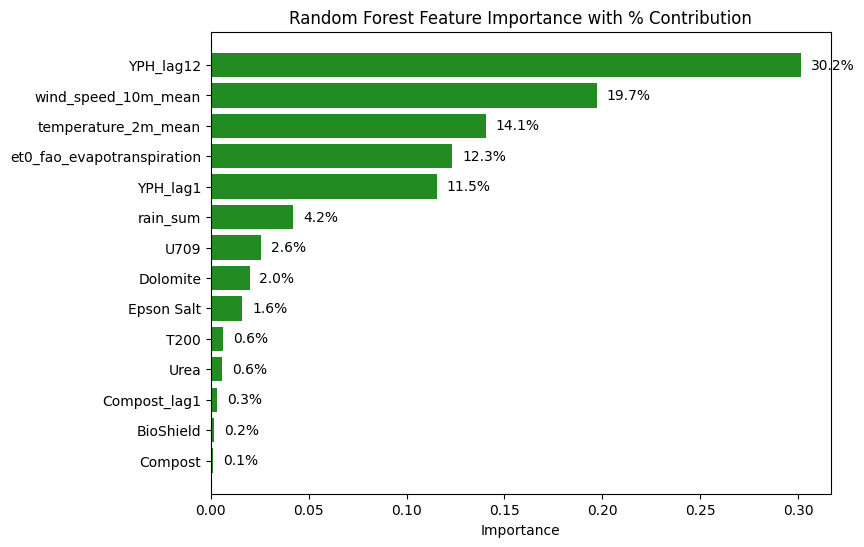

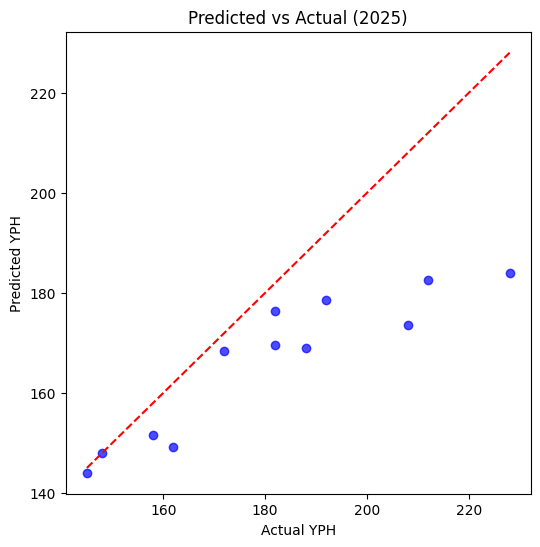

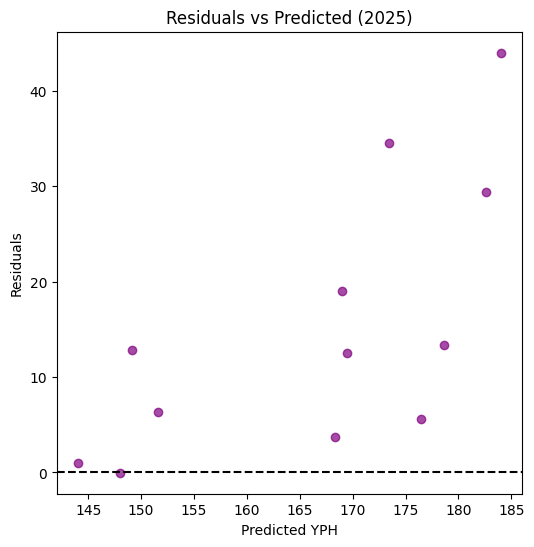

In [25]:
# Convert metrics to DataFrames
train_metrics_df = pd.DataFrame(train_results)
test_metrics_df  = pd.DataFrame(test_results)

# Print metrics
print("\nTRAIN METRICS PER YEAR")
print(train_metrics_df)
print("\nTEST METRICS PER YEAR")
print(test_metrics_df)

print("\nAVERAGE TRAIN METRICS")
print(train_metrics_df[['rmse','mae','mse','r2']].mean())
print("\nAVERAGE TEST METRICS")
print(test_metrics_df[['rmse','mae','mse','r2']].mean())

# Feature importance
rf_model = last_pipeline.named_steps['rf']
feat_imp = pd.DataFrame({
    'feature': features,
    'importance': rf_model.feature_importances_
})
feat_imp['percentage'] = (feat_imp['importance'] / feat_imp['importance'].sum()) * 100
feat_imp = feat_imp.sort_values(by='importance', ascending=False)

# Plot feature importance
plt.figure(figsize=(8,6))
bars = plt.barh(feat_imp['feature'], feat_imp['importance'], color='forestgreen')
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Random Forest Feature Importance with % Contribution")
for bar, pct in zip(bars, feat_imp['percentage']):
    plt.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2, f"{pct:.1f}%", va='center')
plt.show()

# Predicted vs Actual
plt.figure(figsize=(6,6))
plt.scatter(last_y_test, last_y_test_pred, color='blue', alpha=0.7)
plt.plot([last_y_test.min(), last_y_test.max()], [last_y_test.min(), last_y_test.max()], 'r--')
plt.xlabel("Actual YPH")
plt.ylabel("Predicted YPH")
plt.title(f"Predicted vs Actual ({TEST_YEARS[-1]})")
plt.show()

# Residuals vs Predicted
residuals = last_y_test - last_y_test_pred
plt.figure(figsize=(6,6))
plt.scatter(last_y_test_pred, residuals, color='purple', alpha=0.7)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel("Predicted YPH")
plt.ylabel("Residuals")
plt.title(f"Residuals vs Predicted ({TEST_YEARS[-1]})")
plt.show()

### Save Model

In [ ]:
# Save path
save_path = '/content/drive/MyDrive/DSGP_DOCS/Final_Models/random_forest_model.pkl'
os.makedirs(os.path.dirname(save_path), exist_ok=True)

# Save pipeline
joblib.dump(last_pipeline, save_path)
print(f"Random Forest model saved at: {save_path}")

Random Forest model saved at: /content/drive/MyDrive/DSGP_DOCS/Final_Models/random_forest_model.pkl


# **LASSO**

### Model Based Preprocessing

In [26]:
# Create copy
df_lasso = df.copy()

# Create lag features for YPH
for lag in [1, 12]:
    df_lasso[f'YPH_lag{lag}'] = df_lasso['YPH'].shift(lag).bfill()

# Create lag features for fertilizers (1-month lag)
for fert in ['Compost']:
    df_lasso[f'{fert}_lag1'] = df_lasso[fert].shift(1).fillna(0)

# Target & Features
target = 'YPH'
features = [col for col in df_lasso.columns if col not in ['YPH', 'Year']]

# Walk-forward validation settings
TEST_YEARS = sorted(df_lasso[df_lasso['Year'] >= 2020]['Year'].unique())
WINDOW_SIZE = 3
ALPHA = 1.0

### Model Training

In [27]:
train_results = []
test_results  = []

for test_year in TEST_YEARS:

    # Rolling 3-year training window
    train_years = [test_year - i for i in range(WINDOW_SIZE, 0, -1)]

    train_df = df_lasso[df_lasso['Year'].isin(train_years)].copy()
    test_df  = df_lasso[df_lasso['Year'] == test_year].copy()

    X_train = train_df[features]
    y_train = train_df[target]

    X_test = test_df[features]
    y_test = test_df[target]

    print(f"Test Year {test_year} | Train Years {train_years}")

    # Lasso Regression Pipeline
    pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('lasso', Lasso(alpha=ALPHA, random_state=42, max_iter=10000))
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predictions
    y_train_pred = pipeline.predict(X_train)
    y_test_pred  = pipeline.predict(X_test)

    # Store metrics
    train_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'mae': mean_absolute_error(y_train, y_train_pred),
        'mse': mean_squared_error(y_train, y_train_pred),
        'r2': r2_score(y_train, y_train_pred)
    })

    test_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'mae': mean_absolute_error(y_test, y_test_pred),
        'mse': mean_squared_error(y_test, y_test_pred),
        'r2': r2_score(y_test, y_test_pred)
    })

Test Year 2020 | Train Years [np.int64(2017), np.int64(2018), np.int64(2019)]
Test Year 2021 | Train Years [np.int64(2018), np.int64(2019), np.int64(2020)]
Test Year 2022 | Train Years [np.int64(2019), np.int64(2020), np.int64(2021)]
Test Year 2023 | Train Years [np.int64(2020), np.int64(2021), np.int64(2022)]
Test Year 2024 | Train Years [np.int64(2021), np.int64(2022), np.int64(2023)]
Test Year 2025 | Train Years [np.int64(2022), np.int64(2023), np.int64(2024)]


### Model Evaluation and Visualization


TRAIN METRICS PER YEAR
   year      rmse       mae        mse        r2
0  2020  7.706825  5.616723  59.395148  0.897244
1  2021  3.516485  2.383864  12.365665  0.979130
2  2022  1.624787  1.436638   2.639933  0.995892
3  2023  1.609457  1.171200   2.590352  0.996192
4  2024  1.114037  0.876257   1.241078  0.998182
5  2025  1.114051  0.878635   1.241109  0.998189

TEST METRICS PER YEAR
   year      rmse       mae        mse        r2
0  2020  9.535478  7.927765  90.925342  0.849314
1  2021  4.213637  3.435521  17.754734  0.971184
2  2022  0.957273  0.956852   0.916372  0.998513
3  2023  0.839778  0.786702   0.705227  0.998855
4  2024  1.548916  1.149330   2.399140  0.996123
5  2025  1.122589  0.906056   1.260206  0.997963

AVERAGE TRAIN METRICS
year    2022.500000
rmse       2.780940
mae        2.060553
mse       13.245547
r2         0.977472
dtype: float64

AVERAGE TEST METRICS
year    2022.500000
rmse       3.036278
mae        2.527038
mse       18.993504
r2         0.968659
dtype: 

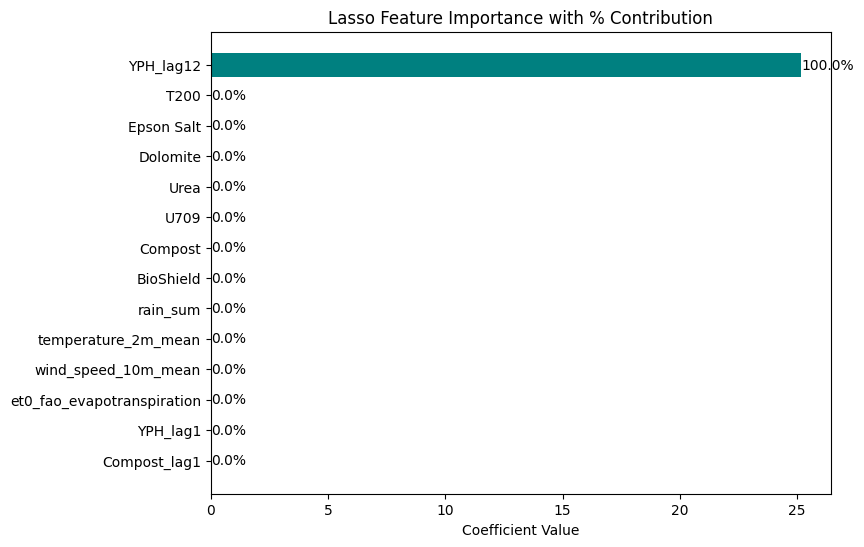

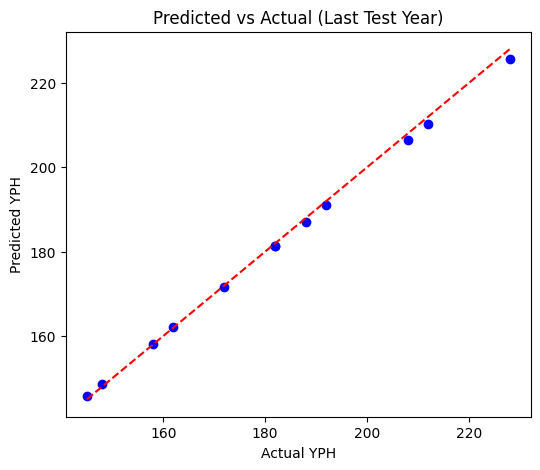

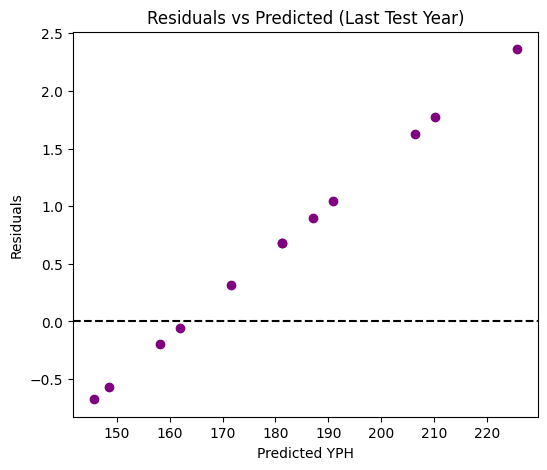

In [28]:
# Create results DataFrames
train_metrics_df = pd.DataFrame(train_results)
test_metrics_df  = pd.DataFrame(test_results)

# Print metrics
print("\nTRAIN METRICS PER YEAR")
print(train_metrics_df)

print("\nTEST METRICS PER YEAR")
print(test_metrics_df)

print("\nAVERAGE TRAIN METRICS")
print(train_metrics_df.mean(numeric_only=True))

print("\nAVERAGE TEST METRICS")
print(test_metrics_df.mean(numeric_only=True))

# Feature Importance (Lasso coefficients)
lasso_model = pipeline.steps[-1][1]

# Create DataFrame
coef_df = pd.DataFrame({
    'feature': features,
    'coefficient': lasso_model.coef_
})

# Absolute value for sorting
coef_df['abs_coef'] = coef_df['coefficient'].abs()
coef_df['percentage'] = (coef_df['abs_coef'] / coef_df['abs_coef'].sum()) * 100

# Sort descending by absolute coefficient
coef_df = coef_df.sort_values(by='abs_coef', ascending=False)

# Plot feature importance with % contribution
plt.figure(figsize=(8,6))
bars = plt.barh(coef_df['feature'], coef_df['coefficient'], color='teal')
plt.gca().invert_yaxis()
plt.xlabel("Coefficient Value")
plt.title("Lasso Feature Importance with % Contribution")

# Add percentage labels to bars
for bar, pct in zip(bars, coef_df['percentage']):
    plt.text(bar.get_width() + np.sign(bar.get_width())*0.02,
             bar.get_y() + bar.get_height()/2,
             f"{pct:.1f}%", va='center')

plt.show()

# Predicted vs Actual
plt.figure(figsize=(6,5))
plt.scatter(y_test, y_test_pred, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual YPH")
plt.ylabel("Predicted YPH")
plt.title("Predicted vs Actual (Last Test Year)")
plt.show()

# Residuals vs Predicted
residuals = y_test - y_test_pred
plt.figure(figsize=(6,5))
plt.scatter(y_test_pred, residuals, color='purple')
plt.axhline(0, color='black', linestyle='--')
plt.xlabel("Predicted YPH")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted (Last Test Year)")
plt.show()

### Save Model

In [ ]:
# Save path
save_path = '/content/drive/MyDrive/DSGP_DOCS/Final_Models/lasso_model.pkl'
os.makedirs(os.path.dirname(save_path), exist_ok=True)

# Save the last trained Lasso pipeline
joblib.dump(pipeline, save_path)
print(f"Lasso pipeline saved at: {save_path}")

Lasso pipeline saved at: /content/drive/MyDrive/DSGP_DOCS/Final_Models/lasso_model.pkl


# **Ridge Regressor**

### Model Based Preprocessing

In [29]:
# Craete copy
df_ridge = df.copy()

# YPH lags (1,12)
for lag in [1, 12]:
    df_ridge[f'YPH_lag{lag}'] = df_ridge['YPH'].shift(lag).bfill()

# Fertilizer lags (1 month)
for fert in ['Compost']:
    df_ridge[f'{fert}_lag1'] = df_ridge[fert].shift(1).fillna(0)

# TARGET & FEATURES
target = 'YPH'
features = [col for col in df_ridge.columns if col not in ['YPH', 'Year']]

# SETTINGS
TEST_YEARS = sorted(df_ridge[df_ridge['Year'] >= 2020]['Year'].unique())
WINDOW_SIZE = 3
ALPHA = 5.0

# Metric storage
train_results = []
test_results  = []

### Model Training

In [30]:
# Walk-Forward Validation
for test_year in TEST_YEARS:

    train_years = [test_year - i for i in range(WINDOW_SIZE, 0, -1)]

    train_df = df_ridge[df_ridge['Year'].isin(train_years)].copy()
    test_df  = df_ridge[df_ridge['Year'] == test_year].copy()

    X_train = train_df[features]
    y_train = train_df[target]

    X_test = test_df[features]
    y_test = test_df[target]

    print(f"Test Year {test_year} | Train Years {train_years}")

    # Ridge pipeline
    pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('ridge', Ridge(alpha=ALPHA, random_state=42))
    ])

    # Train
    pipeline.fit(X_train, y_train)

    # Predictions
    y_train_pred = pipeline.predict(X_train)
    y_test_pred  = pipeline.predict(X_test)

    # Store metrics
    train_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'mae': mean_absolute_error(y_train, y_train_pred),
        'mse': mean_squared_error(y_train, y_train_pred),
        'r2': r2_score(y_train, y_train_pred)
    })

    test_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'mae': mean_absolute_error(y_test, y_test_pred),
        'mse': mean_squared_error(y_test, y_test_pred),
        'r2': r2_score(y_test, y_test_pred)
    })

Test Year 2020 | Train Years [np.int64(2017), np.int64(2018), np.int64(2019)]
Test Year 2021 | Train Years [np.int64(2018), np.int64(2019), np.int64(2020)]
Test Year 2022 | Train Years [np.int64(2019), np.int64(2020), np.int64(2021)]
Test Year 2023 | Train Years [np.int64(2020), np.int64(2021), np.int64(2022)]
Test Year 2024 | Train Years [np.int64(2021), np.int64(2022), np.int64(2023)]
Test Year 2025 | Train Years [np.int64(2022), np.int64(2023), np.int64(2024)]


### Model Evaluation and Visualization


TRAIN METRICS PER YEAR
   year      rmse       mae        mse        r2
0  2020  6.610927  5.192029  43.704359  0.924390
1  2021  3.926405  3.124846  15.416658  0.973981
2  2022  3.747228  3.064690  14.041719  0.978151
3  2023  3.767305  3.057334  14.192588  0.979136
4  2024  3.730960  2.963463  13.920066  0.979613
5  2025  3.633581  2.851506  13.202913  0.980736

TEST METRICS PER YEAR
   year       rmse       mae         mse        r2
0  2020   8.972228  7.147019   80.500879  0.866590
1  2021  10.140896  8.930865  102.837764  0.833093
2  2022   5.531850  4.943611   30.601369  0.950334
3  2023   3.759807  3.300151   14.136150  0.977057
4  2024   4.406028  3.549180   19.413084  0.968625
5  2025   6.881488  5.758828   47.354883  0.923466

AVERAGE TRAIN METRICS
year    2022.500000
rmse       4.236068
mae        3.375645
mse       19.079717
r2         0.969335
dtype: float64

AVERAGE TEST METRICS
year    2022.500000
rmse       6.615383
mae        5.604942
mse       49.140688
r2         0.

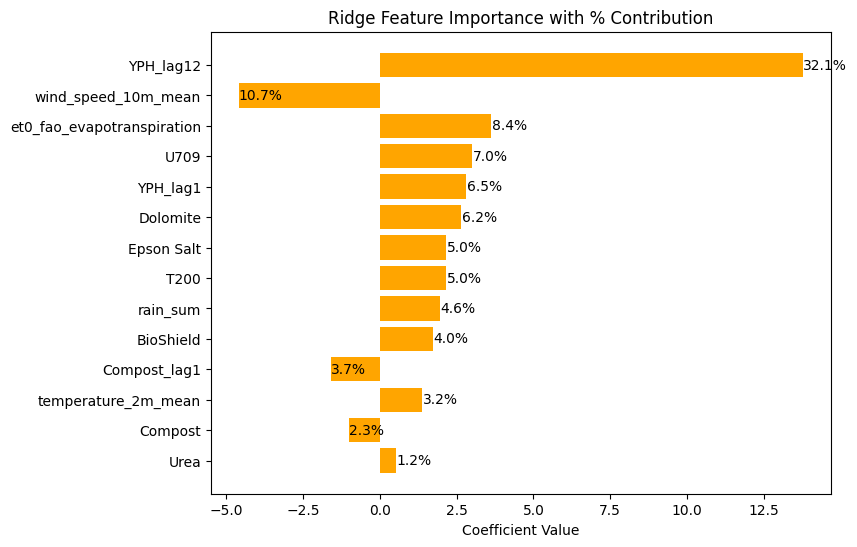

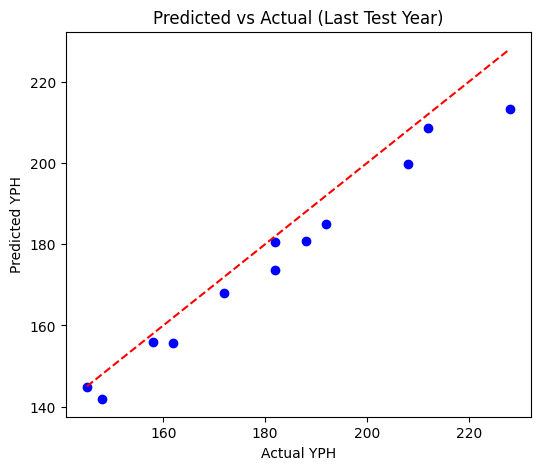

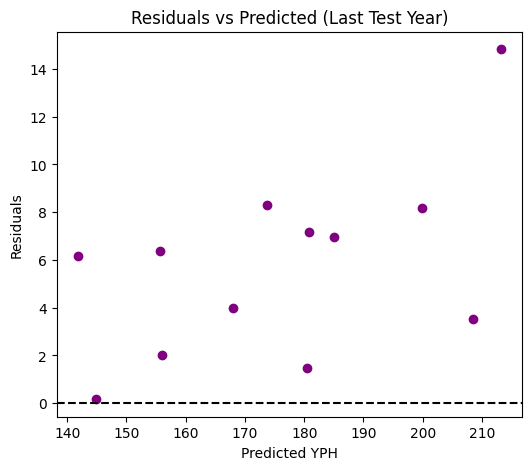

In [31]:
# Results DataFrames
train_metrics_df = pd.DataFrame(train_results)
test_metrics_df  = pd.DataFrame(test_results)

print("\nTRAIN METRICS PER YEAR")
print(train_metrics_df)

print("\nTEST METRICS PER YEAR")
print(test_metrics_df)

print("\nAVERAGE TRAIN METRICS")
print(train_metrics_df.mean(numeric_only=True))

print("\nAVERAGE TEST METRICS")
print(test_metrics_df.mean(numeric_only=True))

# Feature Importance (Ridge coefficients)
ridge_model = pipeline.named_steps['ridge']
coef_df = pd.DataFrame({
    'feature': features,
    'coefficient': ridge_model.coef_
})

# Calculate absolute percentages
coef_df['abs_coef'] = coef_df['coefficient'].abs()
coef_df['percentage'] = (coef_df['abs_coef'] / coef_df['abs_coef'].sum()) * 100

# Sort by absolute coefficient descending
coef_df = coef_df.sort_values(by='abs_coef', ascending=False)

# Plot feature importance
plt.figure(figsize=(8,6))
bars = plt.barh(coef_df['feature'], coef_df['coefficient'], color='orange')
plt.gca().invert_yaxis()
plt.xlabel("Coefficient Value")
plt.title("Ridge Feature Importance with % Contribution")

# Add percentage labels to the bars
for bar, pct in zip(bars, coef_df['percentage']):
    plt.text(bar.get_width() + np.sign(bar.get_width())*0.02, bar.get_y() + bar.get_height()/2,
             f"{pct:.1f}%", va='center')

plt.show()

# Predicted vs Actual (last test year)
plt.figure(figsize=(6,5))
plt.scatter(y_test, y_test_pred, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual YPH")
plt.ylabel("Predicted YPH")
plt.title("Predicted vs Actual (Last Test Year)")
plt.show()

# Residuals vs Predicted
residuals = y_test - y_test_pred
plt.figure(figsize=(6,5))
plt.scatter(y_test_pred, residuals, color='purple')
plt.axhline(0, color='black', linestyle='--')
plt.xlabel("Predicted YPH")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted (Last Test Year)")
plt.show()

### Save Model

In [ ]:
# Save path
save_path = '/content/drive/MyDrive/DSGP_DOCS/Final_Models/ridge_model.pkl'
os.makedirs(os.path.dirname(save_path), exist_ok=True)

# Save the last trained Ridge pipeline
joblib.dump(pipeline, save_path)
print(f"Ridge pipeline saved at: {save_path}")

Ridge pipeline saved at: /content/drive/MyDrive/DSGP_DOCS/Final_Models/ridge_model.pkl


# **Neural Networks**

### Model Based Preprocessing

In [44]:
# Create copy
df_nn = df.copy()

# YPH lags (1, 12 months)
for lag in [1, 12]:
    df_nn[f'YPH_lag{lag}'] = df_nn['YPH'].shift(lag).bfill()

# Fertilizer lags (1 month)
for fert in ['Compost']:
    df_nn[f'{fert}_lag1'] = df_nn[fert].shift(1).fillna(0)

# Target & Features
target = 'YPH'
features = [col for col in df_nn.columns if col not in ['YPH', 'Year']]

# Walk-forward validation
TEST_YEARS = sorted(df_nn[df_nn['Year'] >= 2020]['Year'].unique())
WINDOW_SIZE = 3

# Metric storage
train_results = []
test_results = []

### Model Training

In [45]:
for test_year in TEST_YEARS:
    # 1. Data Selection
    train_years = [test_year - i for i in range(WINDOW_SIZE, 0, -1)]
    train_df = df_nn[df_nn['Year'].isin(train_years)].copy()
    test_df  = df_nn[df_nn['Year'] == test_year].copy()

    X_train, y_train = train_df[features].values, train_df[target].values
    X_test, y_test   = test_df[features].values, test_df[target].values

    # 2. Scaling (Both X and y)
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train)
    X_test_scaled  = scaler_X.transform(X_test)

    # Scale Y - important for NN performance
    y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).flatten()

    # 3. Model Definition
    model = Sequential([
        Dense(16, activation='relu', kernel_initializer='he_normal', input_shape=(X_train_scaled.shape[1],)),
        Dropout(0.2),
        Dense(8, activation='relu'),
        Dense(1)
    ])

    # Use a specific learning rate
    model.compile(optimizer=Adam(learning_rate=0.01), loss='mse')

    model.fit(
        X_train_scaled, y_train_scaled,
        epochs=100,
        batch_size=4,
        verbose=0
    )

    # 5. Predictions & Inverse Scaling
    y_train_pred_scaled = model.predict(X_train_scaled)
    y_test_pred_scaled  = model.predict(X_test_scaled)

    # Bring values back to original scale (e.g., from 0.5 back to 140.0)
    y_train_pred = scaler_y.inverse_transform(y_train_pred_scaled).flatten()
    y_test_pred  = scaler_y.inverse_transform(y_test_pred_scaled).flatten()

    # 6. Store metrics (Using unscaled y values)
    train_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'mae': mean_absolute_error(y_train, y_train_pred),
        'mse': mean_squared_error(y_train, y_train_pred),
        'r2': r2_score(y_train, y_train_pred)
    })

    test_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'mae': mean_absolute_error(y_test, y_test_pred),
        'mse': mean_squared_error(y_test, y_test_pred),
        'r2': r2_score(y_test, y_test_pred)
    })

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


...

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


### Model Evaluation


TRAIN METRICS PER YEAR
   year      rmse       mae        mse        r2
0  2020  3.992542  3.131563  15.940394  0.972422
1  2021  3.483252  2.591519  12.133042  0.979523
2  2022  3.798620  3.114178  14.429516  0.977548
3  2023  4.105035  2.990475  16.851311  0.975228
4  2024  3.840000  3.285731  14.745601  0.978404
5  2025  4.252362  3.192087  18.082586  0.973616

TEST METRICS PER YEAR
   year       rmse        mae         mse        r2
0  2020   6.377306   5.724295   40.670029  0.932600
1  2021  13.190691  11.225010  173.994339  0.717605
2  2022   7.799313   5.936520   60.829288  0.901273
3  2023   7.025347   6.074188   49.355499  0.919895
4  2024   7.314109   5.699518   53.496189  0.913541
5  2025   4.427173   3.644563   19.599859  0.968323

AVERAGE TRAIN METRICS
year    2022.500000
rmse       3.911969
mae        3.050926
mse       15.363742
r2         0.976123
dtype: float64

AVERAGE TEST METRICS
year    2022.500000
rmse       7.688990
mae        6.384016
mse       66.324201
r2    

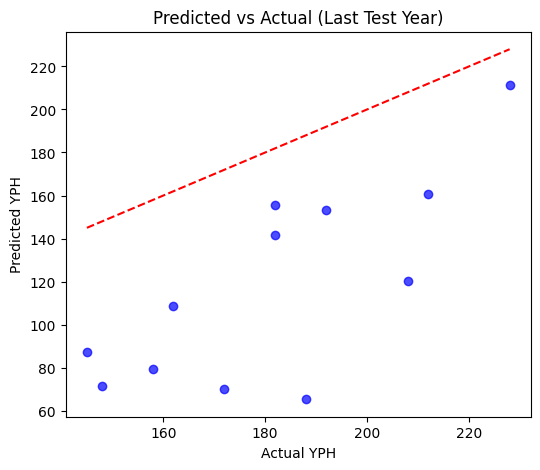

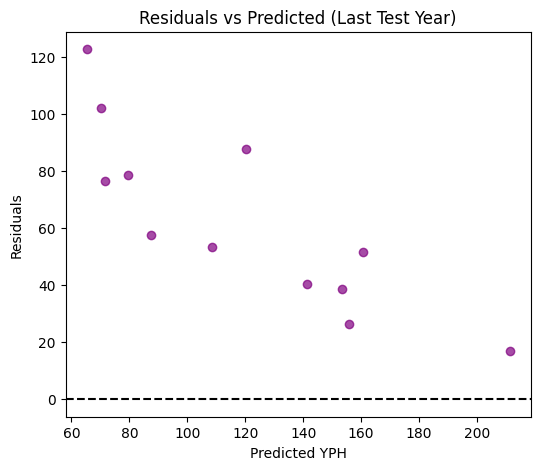

In [46]:
# Metrics DataFrames
train_metrics_df = pd.DataFrame(train_results)
test_metrics_df  = pd.DataFrame(test_results)

print("\nTRAIN METRICS PER YEAR")
print(train_metrics_df)
print("\nTEST METRICS PER YEAR")
print(test_metrics_df)

print("\nAVERAGE TRAIN METRICS")
print(train_metrics_df.mean(numeric_only=True))
print("\nAVERAGE TEST METRICS")
print(test_metrics_df.mean(numeric_only=True))

# Predicted vs Actual Plot
plt.figure(figsize=(6,5))
plt.scatter(last_y_test, last_y_test_pred, color='blue', alpha=0.7)
plt.plot([last_y_test.min(), last_y_test.max()],
         [last_y_test.min(), last_y_test.max()], 'r--')
plt.xlabel("Actual YPH")
plt.ylabel("Predicted YPH")
plt.title("Predicted vs Actual (Last Test Year)")
plt.show()

# Residuals vs Predicted
residuals = last_y_test - last_y_test_pred
plt.figure(figsize=(6,5))
plt.scatter(last_y_test_pred, residuals, color='purple', alpha=0.7)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel("Predicted YPH")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted (Last Test Year)")
plt.show()

### Save Model

In [ ]:
# Path to save
save_path = '/content/drive/MyDrive/DSGP_DOCS/Final_Models/nn_model.h5'
os.makedirs(os.path.dirname(save_path), exist_ok=True)

# Save model
model.save(save_path)
print(f"Neural Network model saved at: {save_path}")

Neural Network model saved at: /content/drive/MyDrive/DSGP_DOCS/Final_Models/nn_model.h5
